# Jet turbulence (Modane): data and MGD model
Data: velocity record of the Modane wind tunnel. Model: run `jets_full`, 5 seeds (500–504)
(wavelet marginals on the Morlet bank, Q = 1; scattering coefficients of order 1 to 4; $L^6$ norm).
$\Theta$ = $\Theta_{\rm reg}$ at the last time step of the transport ($t \approx 1$), $\lambda = 10^{-2}$.

Run on Jean Zay from `jets/`. Uses `figures/logp_jets/logp_jets.npz` (`python jets/logp_jets.py`). Figures: `figures/talk/`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
ROOT = Path.cwd()                                   # jets/
for p in ('codes', 'codes/filters', 'codes/potentials', 'data', 'turbulence', 'jets'):
    sys.path.insert(0, str(ROOT.parent / p))
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display
import talk_figures as tf
import run_comparison as rc
from logp_family_contrib import load_potentials
tf.set_output(ROOT / 'figures' / 'talk')          # every figure is also saved here as PNG

In [2]:
import jets_compare as jc
import logp_jets as lj
from jet_data import load_modane_raw
LABEL, SEEDS = 'jets_full', [500, 501, 502, 503, 504]
configs = jc.find_seed_configs(ROOT, LABEL, SEEDS)
runs = {s: rc.load_config(c, ROOT, label=LABEL, extras=False) for s, c in configs.items()}
cfg = runs[SEEDS[0]]['cfg']
x1 = jc.reference_data(cfg).numpy()                                   # training data (n, T), standardized
xt = np.concatenate([r['xt'].numpy() for r in runs.values()])         # generated signals, 5 seeds
L = lj.load(ROOT / 'figures' / 'logp_jets' / 'logp_jets.npz')['jets_full']
assert sorted(int(s) for s in L['seeds']) == SEEDS and L['C']['train'].shape[-1] == len(x1)
# Theta(t = 1) of seed 500 at the selected lambda (the file logp_jets.py used)
from logp_seed_check import XSEED
xsel = torch.load(XSEED / 'xseed_jets_full.pt', map_location='cpu', weights_only=False)
sol = torch.load(xsel['theta_files']['end0.99'][configs[SEEDS[0]]], map_location='cpu', weights_only=False)
assert sol['config'] == configs[SEEDS[0]] and float(sol['lam']) == L['lam'], (sol['config'], sol['lam'])
theta = sol['Theta_reg'][-1].double().numpy()
print('data', x1.shape, '| generated', xt.shape, '| lambda', L['lam'])

data (10000, 256) | generated (50000, 256) | lambda 0.01


## Contribution of each potential family to −log p
For each data signal, $C_F(x) = -\Theta_F \cdot \phi_F(x)$, and $-\log p(x) = \sum_F C_F(x)$ + constant.
Top: mean over signals (its zero is arbitrary: a constant added to $\phi_F$ changes it, not $p$).
Middle: standard deviation across signals. Bottom: the same divided by the standard deviation of $-\log p$.
Error bars: standard deviation over the 5 seeds.

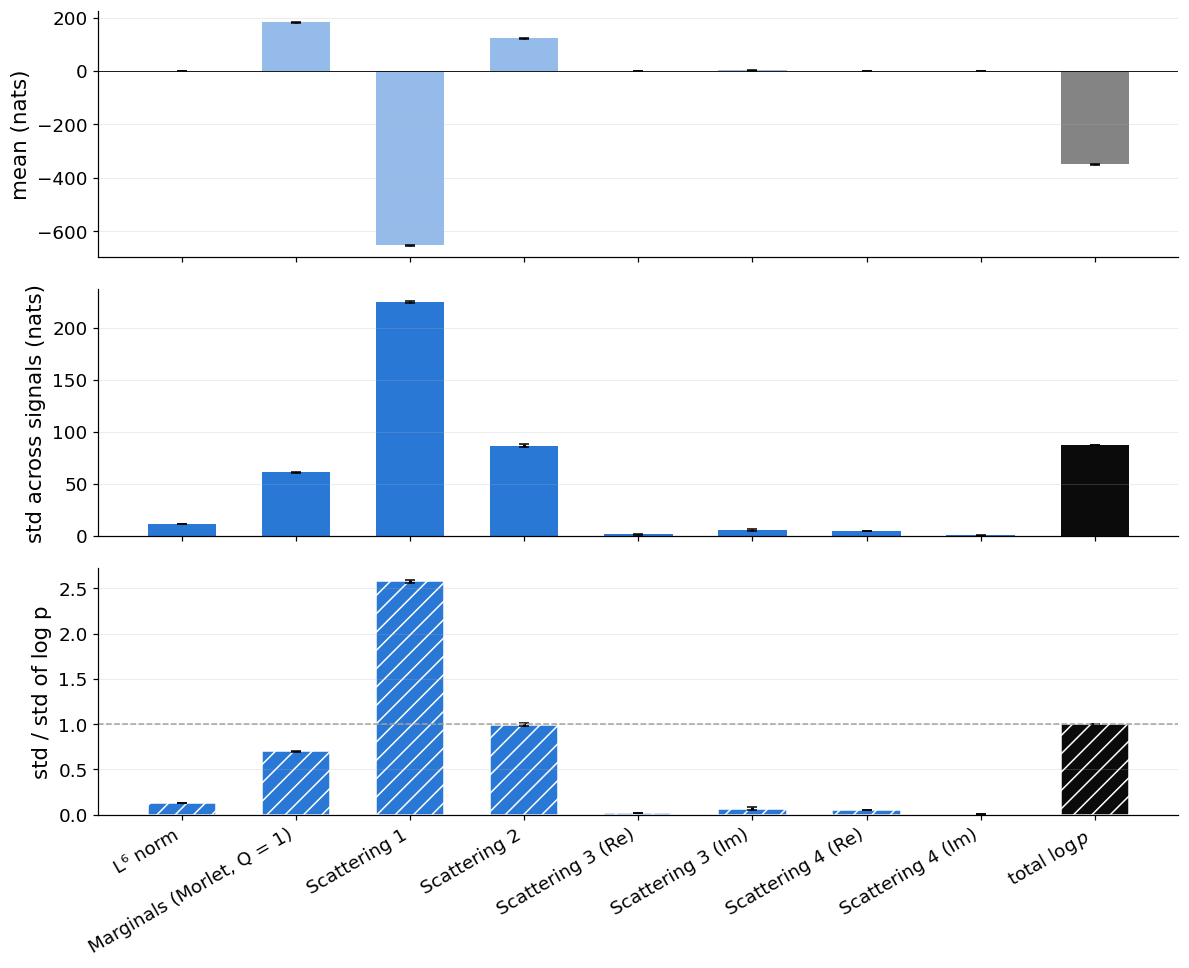

In [3]:
C = L['C']['train']                                   # (seeds, families + total, signals)
tf.plot_energy_bars({f: C[:, i] for i, f in enumerate(L['families'])}, 'logp_per_family')

## Distribution of −log p over the data
$-\log p(x) = -\Theta \cdot \phi(x)$ up to a constant, for the training signals; each seed relative to its own
median, the 5 seeds pooled. The contribution of the third- and fourth-order scattering terms is in the figure above.

In [ ]:
tf.plot_logp_histogram(np.concatenate([c[-1] - np.median(c[-1]) for c in C]), 'neglogp_data', min_freq=1e-4)   # -log p

## Signals ranked by −log p, from the most typical to the rarest
Left: $-\log p$ of all the signals, relative to the median. Arrows: 10 evenly spaced values from the lowest (most typical) to the highest (rarest) $-\log p$; right: the signal closest to each value, same colour, $-\log p$ on top.
The support is cut where the frequency per bin falls below $10^{-4}$ (isolated outliers are not picked), as in the Lagrangian case.
First figure: generated signals (seed 500), with the $\log p$ of the model that generated them. Second: the training signals, with the $\log p$ that same model gives them. Needs `python jets/logp_generated_jets.py` (GPU).

In [ ]:
G = np.load(ROOT / 'figures' / 'logp_jets' / 'logp_generated_jets_full.npz')       # python jets/logp_generated_jets.py
assert [int(s) for s in G['seeds']] == SEEDS and abs(float(G['lam']) - L['lam']) < 1e-12
ks = 0                                                                              # index of seed 500
xt_s = runs[SEEDS[ks]]['xt'].numpy()
assert len(xt_s) == G['logp'].shape[1], (len(xt_s), G['logp'].shape)
tf.plot_ranked_signals(xt_s, G['logp'][ks], 'generated_ranked', n=10, min_freq=1e-4)
tf.plot_ranked_signals(x1, C[ks, -1], 'data_ranked', n=10, min_freq=1e-4)           # same for the data (C = log p of the training signals)

## −log p for a Gaussian with the jets spectrum
Training signals: 10000 draws of the stationary Gaussian whose power spectrum is the Modane spectrum (averaged over the
training windows), not white noise. Model: MGD with second-order scattering only (Q = 1), run `jets_gauss_spectrum`,
$\Theta_{\rm reg}$ with $\lambda = 5\cdot10^{-4}$. Here the true $-\log p$ is known exactly.
Left: exact (black) and MGD (blue) $-\log p$ of the training signals, each relative to the mean over its own law's samples.
Right: MGD against exact, one point per signal. Needs `python turbulence/logp_gauss_scat2.py ... --outdir jets/saved_results/gauss_spectrum_logp` (gauss_spectrum/README.md).

In [ ]:
tf.plot_logp_gaussian(ROOT / 'saved_results' / 'gauss_spectrum_logp' / 'all_seeds.npz', 'logp_gauss_spectrum')

## Wavelet coefficients of the data, per scale
Real part of the Morlet wavelet coefficients, one panel per scale $j$, divided by their standard deviation.
Dashed: standard Gaussian.

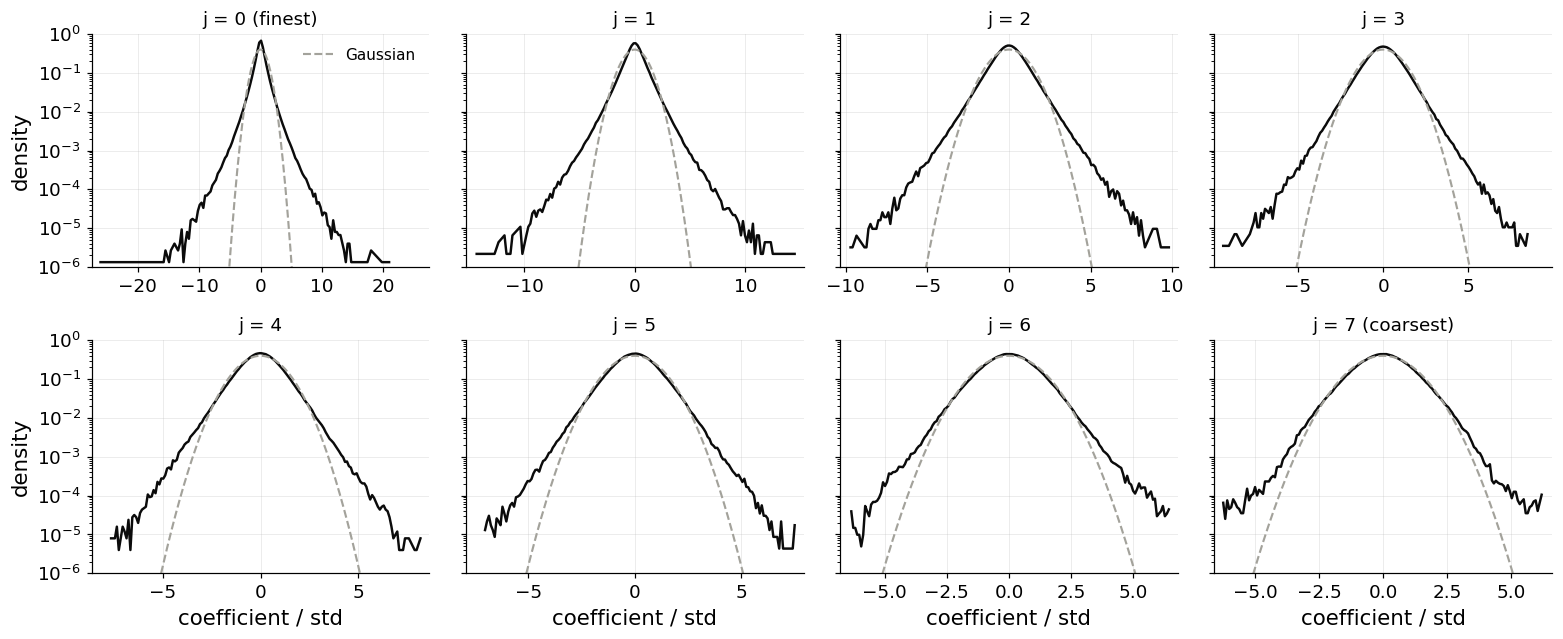

In [5]:
tf.plot_wavelet_histograms(x1, int(cfg['J']), 'data_wavelet_histograms')

## Statistics of the draft's Fig. 6: data and model
Same formulas as the draft (`turbulence/paper_figs_ensemble.curves`), talk style, lags in samples; 3 figures of 3 panels.
Skewness of the power increments $(x(t+\tau) - x(t))\,x(t)$ (`skew_mode='power'`, as in the draft).
Bands: `tf.BAND` (`'seeds'`: mean ± std over the seeds; `'batch'`: min / max over 10 batches of one run).

In [ ]:
xts = [r['xt'].numpy() for r in runs.values()]                       # one array per seed
tf.BAND = 'seeds'                                                      # 'batch': min/max over batches of all seeds pooled
st6 = tf.fig6_stats(x1, xts, tau_star=20, skew_mode='power')
tf.plot_fig6(st6, 'fig6_eulerian')

## Signals, zoomed
Top: 6 stretches of 500 samples of the raw record (standardized), chosen at random.
Bottom: 6 generated signals (256 samples; one sample = 2 raw samples).

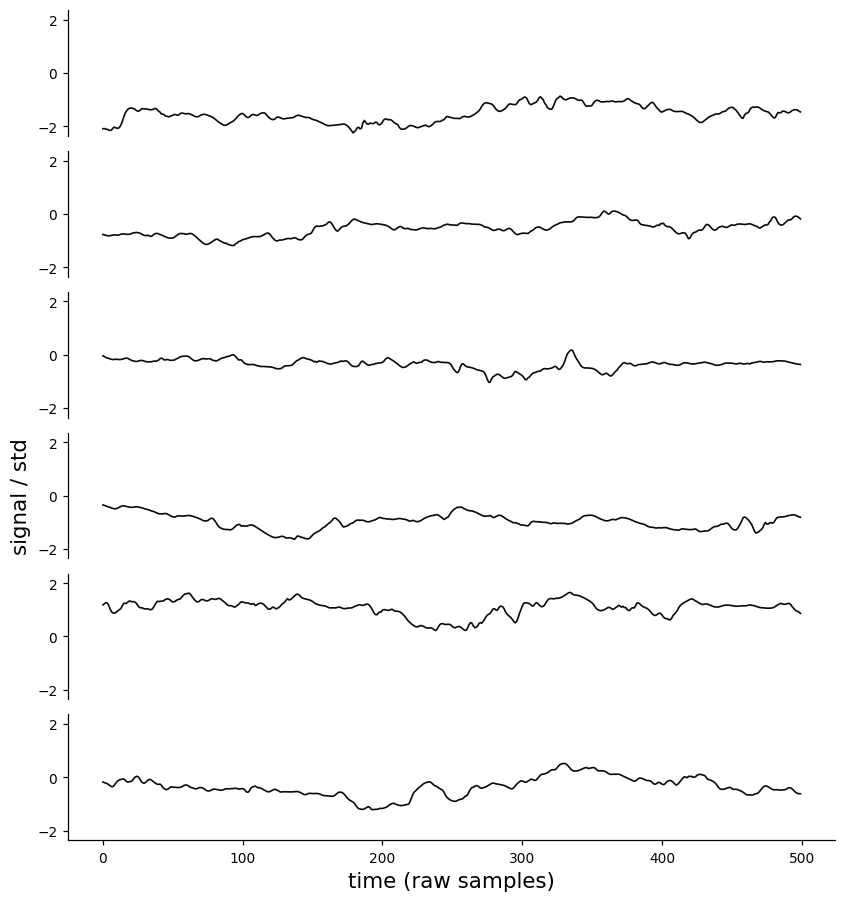

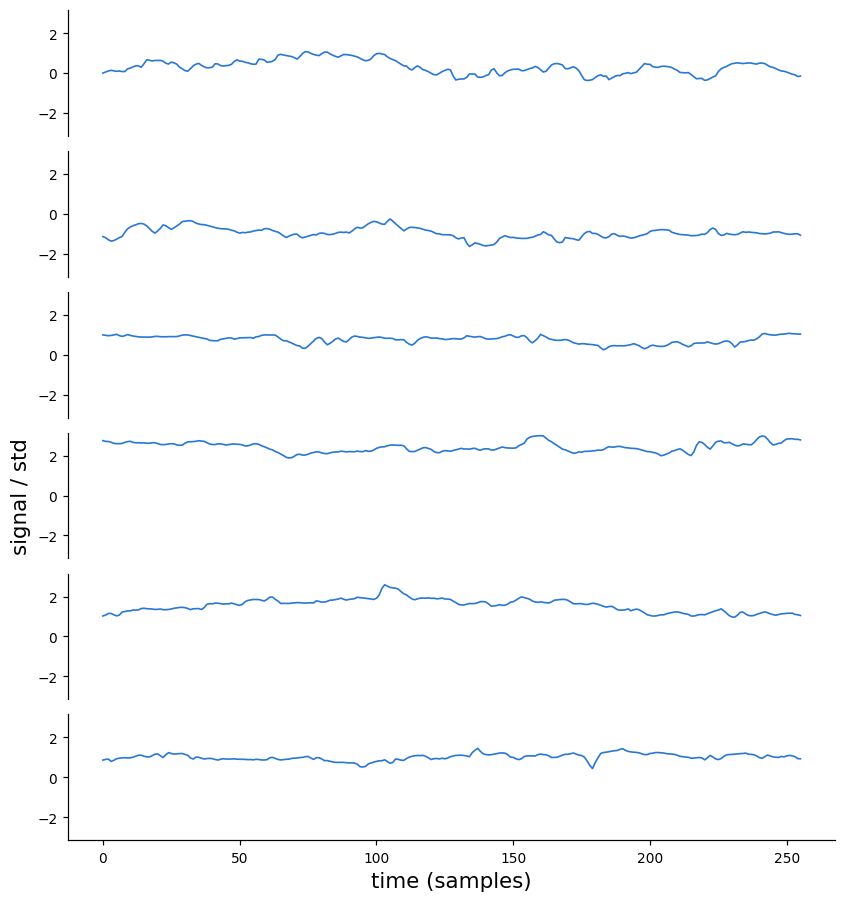

In [6]:
u = load_modane_raw()
u = (u - u.mean()) / u.std()
rng = np.random.default_rng(0)
starts = rng.choice(len(u) - 500, 6, replace=False)
tf.plot_signals(np.stack([u[s:s + 500] for s in starts]), 'raw_record_zoom', xlabel='time (raw samples)')
tf.plot_signals(xt[rng.choice(len(xt), 6, replace=False)], 'generated_signals', color=tf.MODEL)

## Three clean signals (Eulerian)
Slide format: no axes, no $\tau$, no markers. Three signals drawn at random from the training data (`seed=None`: new ones at every run, indices printed).
Each figure is also saved with axes (`*_axes_k.png`, same signals): $x/\sigma(x)$ on the vertical axis (amplitude in standard deviations), time on the horizontal axis.

In [ ]:
tf.plot_clean_signals(x1, 'clean_eulerian', n=3)                                   # + clean_eulerian_axes_1..3.png

## Number of statistics in the model
Per potential family, as used in the run (seed 500; after removing duplicate filters and empty windows).

In [ ]:
from logp_family_contrib import phi_matrix
exp = rc._find_exp_dir(ROOT, configs[SEEDS[0]])
pots = load_potentials(exp, cfg, 'cpu')
xs = torch.as_tensor(x1[:200]).reshape(200, 1, -1).float()
# check: log p of 200 data signals recomputed here = the saved values (same Theta, potentials and sign)
lp_check = phi_matrix(pots, xs) @ theta
# compared with the saved log p in the next two cells (overall, then per family); no assert: they print the size
n_stats = tf.count_statistics(pots, xs, theta, Q=cfg['Q'])
n_stats.to_csv(ROOT / 'figures' / 'talk' / 'number_of_statistics.csv')
display(n_stats)

In [8]:
saved = C[[int(s) for s in L['seeds']].index(SEEDS[0]), -1][:200]
diff = lp_check - saved
print(f'max |diff| {np.abs(diff).max():.4g} nats | mean diff {diff.mean():.4g} | std of log p across signals {saved.std():.4g}'
      f' | corr {np.corrcoef(lp_check, saved)[0, 1]:.8f}')
print('recomputed', np.round(lp_check[:4], 3), '\nsaved     ', np.round(saved[:4], 3))

max |diff| 44.97 nats | mean diff -1.504 | std of log p across signals 79.66 | corr 0.99670447
recomputed [-359.212 -359.642 -241.007 -246.273] 
saved      [-355.778 -360.328 -242.945 -247.204]


In [9]:
from check_potentials import theta_column_map
cmap = theta_column_map(pots, len(theta))
phi = phi_matrix(pots, xs)
seeds = [int(s) for s in L['seeds']]
k = seeds.index(SEEDS[0])
print('per family, seed', SEEDS[0])
for i, (name, (a, w)) in enumerate(cmap.items()):
    rec, sav = phi[:, a:a + w] @ theta[a:a + w], C[k, i, :200]
    print(f'  {name:40s} max|diff| {np.abs(rec - sav).max():10.4g}   mean|C| {np.abs(sav).mean():10.4g}   corr {np.corrcoef(rec, sav)[0, 1]:.6f}')
print('total recomputed vs each saved seed:')
for j, s in enumerate(seeds):
    print(f'  seed {s}: max|diff| {np.abs(phi @ theta - C[j, -1, :200]).max():.4g}')


per family, seed 500
  L_6                                      max|diff|  3.613e-05   mean|C|      1.455   corr 1.000000
  Scalar_morlet_gaussianK                  max|diff|  0.0001653   mean|C|      176.3   corr 1.000000
  Scattering_First_Order                   max|diff|  0.0003092   mean|C|      638.2   corr 1.000000
  Scattering_Second_Order                  max|diff|  0.0001608   mean|C|      118.6   corr 1.000000
  Scattering_Third_Order_Real              max|diff|  3.718e-06   mean|C|     0.6493   corr 1.000000
  Scattering_Third_Order_Imag              max|diff|      44.97   mean|C|      3.591   corr 0.006425
  Scattering_Fourth_Order_Mod2_Real_Q1     max|diff|  3.574e-05   mean|C|      1.444   corr 1.000000
  Scattering_Fourth_Order_Mod2_Imag_Q1     max|diff|  1.533e-06   mean|C|    0.06439   corr 1.000000
total recomputed vs each saved seed:
  seed 500: max|diff| 44.97
  seed 501: max|diff| 49.85
  seed 502: max|diff| 48.21
  seed 503: max|diff| 43.41
  seed 504: max|diff| 

## Energy table: categories of statistics (Lagrangian and Eulerian)
Scalar multiscale moments (Scat1, Scat2, marginals) · order 3 Re / Im (Scat3) · order 4 Re / Im (Scat4) · confinement ($L^6$, last column). Number of moments, then mean and std over signals of each category's contribution to $-\log p$; each value averaged over the 5 seeds, ± = std over the seeds. The Lagrangian block is read from talk_turbulence.ipynb's CSV (run it first: the CSV format changed on 11-04).

In [ ]:
fam_j = [f for f in L['families'] if f.lower() != 'total']
assert len(fam_j) == len(cmap), (fam_j, list(cmap))
widths_j = {f: w for f, (a, w) in zip(fam_j, cmap.values())}       # same order as the per-family check above
E_eul = tf.energy_table({f: C[:, i] for i, f in enumerate(L['families']) if f.lower() != 'total'}, widths_j,
                        'energy_table_eulerian')
display(E_eul)
tf.plot_energy_table_single(E_eul, 'energy_table_eulerian', 'Eulerian')          # Eulerian alone
lag_csv = ROOT.parent / 'turbulence' / 'figures' / 'talk' / 'energy_table_lagrangian.csv'
tabs = {'Lagrangian': pd.read_csv(lag_csv, index_col=0)} if lag_csv.exists() else {}
print('Lagrangian block:', 'from ' + str(lag_csv) if tabs else 'MISSING (run talk_turbulence.ipynb first)')
tabs['Eulerian'] = E_eul
tf.plot_energy_table(tabs, 'energy_table')                                      # both, one block each